In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('XGBoost not installed. Run: pip install xgboost')
try:
    from lightgbm import LGBMRegressor
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
    print('LightGBM not installed. Run: pip install lightgbm')

## 1. Load & Clean Data

In [3]:
df = pd.read_csv('ram.csv')

def convert_to_mb(val):
    val = str(val).lower().strip()
    if 'gb' in val:
        return float(val.replace('gb', '')) * 1024
    elif 'g' in val:
        return float(val.replace('g', '')) * 1024
    elif 'mb' in val:
        return float(val.replace('mb', ''))
    elif 'm' in val:
        return float(val.replace('m', ''))
    else:
        return float(val)

df['device_write'] = df['device_write'].apply(convert_to_mb)
df['memory'] = df['memory'].apply(convert_to_mb)

print('Shape before cleaning:', df.shape)
print('\nResponseTime stats:')
print(df['ResponseTime'].describe())

Shape before cleaning: (1215, 8)

ResponseTime stats:
count      1215.000000
mean      11388.569630
std       25217.896043
min           2.400000
25%           4.100000
50%        1456.300000
75%       10171.150000
max      218537.800000
Name: ResponseTime, dtype: float64


In [4]:
n_before = len(df)
df = df[df['ResponseTime'] > 0].copy()
print(f'Removed {n_before - len(df)} rows with ResponseTime <= 0')

p99 = df['ResponseTime'].quantile(0.99)
hard_cap = 100000  # ms
remove_threshold = min(p99, hard_cap)

n_before = len(df)
df = df[df['ResponseTime'] <= remove_threshold].copy()
n_removed = n_before - len(df)

p95 = df['ResponseTime'].quantile(0.95)
df['ResponseTime'] = df['ResponseTime'].clip(upper=p95)

print(f'99th percentile RT: {p99:.1f} ms')
print(f'Hard cap:           {hard_cap} ms')
print(f'Remove threshold:   {remove_threshold:.1f} ms (stricter of the two)')
print(f'Rows removed:       {n_removed}')
print(f'Winsorize cap (p95):{p95:.1f} ms')

print('\nColumn value counts (unique):')
for col in df.columns:
    print(f'  {col}: {df[col].nunique()} unique values')

cols_to_drop = [col for col in df.columns if df[col].nunique() == 1]
print(f'\nDropping constant columns: {cols_to_drop}')
df.drop(columns=cols_to_drop, inplace=True)

if 'Throughput' in df.columns:
    df.drop(columns=['Throughput'], inplace=True)
    print('Dropped Throughput (target leakage)')

print(f'\nFinal shape: {df.shape}')
print('Remaining features:', list(df.columns))

Removed 0 rows with ResponseTime <= 0
99th percentile RT: 123778.0 ms
Hard cap:           100000 ms
Remove threshold:   100000.0 ms (stricter of the two)
Rows removed:       24
Winsorize cap (p95):44876.3 ms

Column value counts (unique):
  ArrivalRate: 5 unique values
  device_write: 3 unique values
  cpus: 3 unique values
  memory: 3 unique values
  cpuLoad: 3 unique values
  size: 3 unique values
  Throughput: 281 unique values
  ResponseTime: 769 unique values

Dropping constant columns: []
Dropped Throughput (target leakage)

Final shape: (1191, 7)
Remaining features: ['ArrivalRate', 'device_write', 'cpus', 'memory', 'cpuLoad', 'size', 'ResponseTime']


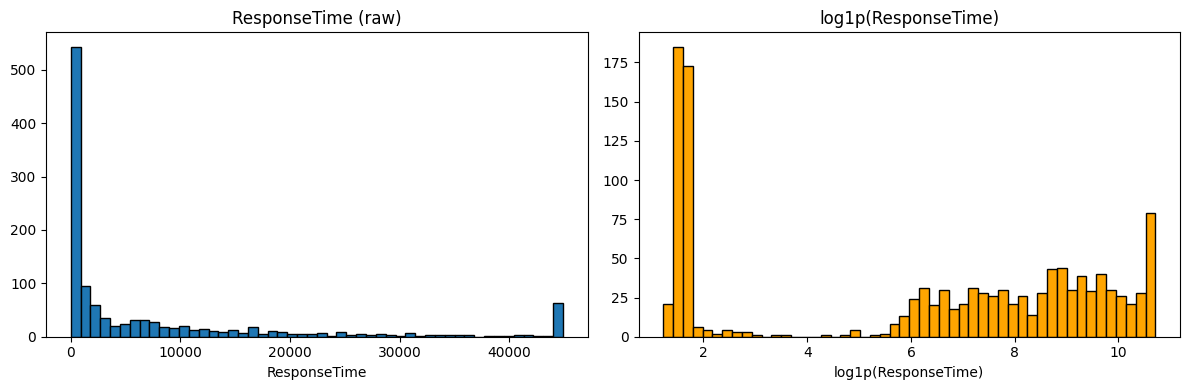

In [5]:
# Visualize the target distribution — should be right-skewed
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['ResponseTime'], bins=50, edgecolor='black')
axes[0].set_title('ResponseTime (raw)')
axes[0].set_xlabel('ResponseTime')

axes[1].hist(np.log1p(df['ResponseTime']), bins=50, edgecolor='black', color='orange')
axes[1].set_title('log1p(ResponseTime)')
axes[1].set_xlabel('log1p(ResponseTime)')

plt.tight_layout()
plt.show()
# If the right plot looks more bell-shaped, log-transform is the right call.

## 2. Feature Engineering & Split

Raw features alone may not capture non-linear interactions (e.g. high ArrivalRate + high IO size = exponential RT blowup). Adding interaction and ratio features gives the models more signal.

In [6]:
def add_features(df):
    d = df.copy()
    if 'ArrivalRate' in d.columns and 'cpuLoad' in d.columns:
        d['rate_x_cpuLoad'] = d['ArrivalRate'] * d['cpuLoad']
    if 'ArrivalRate' in d.columns and 'size' in d.columns:
        d['rate_x_size'] = d['ArrivalRate'] * d['size']
    if 'cpuLoad' in d.columns and 'size' in d.columns:
        d['cpuLoad_x_size'] = d['cpuLoad'] * d['size']
    if 'size' in d.columns and 'cpus' in d.columns:
        d['size_per_cpu'] = d['size'] / (d['cpus'] + 1e-6)
    if 'ArrivalRate' in d.columns and 'cpus' in d.columns:
        d['rate_per_cpu'] = d['ArrivalRate'] / (d['cpus'] + 1e-6)
    if all(c in d.columns for c in ['ArrivalRate', 'cpuLoad', 'size']):
        d['rate_x_cpu_x_size'] = d['ArrivalRate'] * d['cpuLoad'] * d['size']
    return d

df_feat = add_features(df)
feature_cols = [c for c in df_feat.columns if c != 'ResponseTime']
X = df_feat[feature_cols]
y_raw = df['ResponseTime']

# Log-transform target — reduces skew, helps all models (especially linear & MLP)
y = np.log1p(y_raw)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Keep the raw (untransformed) test target for final error metrics
y_test_raw = np.expm1(y_test)

print('Train size:', len(X_train))
print('Test size:', len(X_test))
print('Features:', feature_cols)

Train size: 952
Test size: 239
Features: ['ArrivalRate', 'device_write', 'cpus', 'memory', 'cpuLoad', 'size', 'rate_x_cpuLoad', 'rate_x_size', 'cpuLoad_x_size', 'size_per_cpu', 'rate_per_cpu', 'rate_x_cpu_x_size']


## 3. Metrics

In [7]:
def smape(y_true, y_pred):
    """Symmetric MAPE — safe against near-zero values."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(
        2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-6)
    ) * 100

def mape_safe(y_true, y_pred, clip_min=1.0):
    """MAPE with a minimum clip on y_true to avoid huge errors from near-zero rows."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    y_true_clipped = np.clip(np.abs(y_true), clip_min, None)
    return np.mean(np.abs(y_true - y_pred) / y_true_clipped) * 100

def p90_error(y_true, y_pred):
    """90th percentile of absolute percentage error."""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    y_true_clipped = np.clip(np.abs(y_true), 1.0, None)
    errors = np.abs((y_true - y_pred) / y_true_clipped) * 100
    return np.percentile(errors, 90)

def evaluate(name, y_true_raw, y_pred_log, y_test_log):
    """Convert log predictions back to original scale, then compute metrics."""
    y_pred_raw = np.expm1(y_pred_log)
    print(f'{name}')
    print(f'  R²:     {r2_score(y_test_log, y_pred_log):.4f}  (log scale)')
    print(f'  RMSE:   {np.sqrt(mean_squared_error(y_true_raw, y_pred_raw)):.1f}')
    print(f'  SMAPE:  {smape(y_true_raw, y_pred_raw):.2f}%')
    print(f'  MAPE:   {mape_safe(y_true_raw, y_pred_raw):.2f}%')
    print(f'  P90:    {p90_error(y_true_raw, y_pred_raw):.2f}%')
    print()

## 4. Train Models

All scaled models use a `Pipeline` (scaler + model) to avoid data leakage.
RF, XGB, LGB don't need scaling — they're tree-based.

In [8]:
# ── Linear models (Ridge is better than vanilla LR on correlated features) ──
ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=1.0))
])
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

# ── SVR ──
svr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVR(kernel='rbf', C=10, epsilon=0.1))
])
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)

# ── MLP ──
mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPRegressor(hidden_layer_sizes=(128, 64, 32), max_iter=1000,
                           early_stopping=True, random_state=42))
])
mlp.fit(X_train, y_train)
y_pred_mlp = mlp.predict(X_test)

# ── Random Forest (tuned) ──
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# ── Gradient Boosting (sklearn — no extra install needed) ──
gb = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42
)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print('Core models trained.')

Core models trained.


In [9]:
# # ── XGBoost (if available) ──
# if HAS_XGB:
#     xgb = XGBRegressor(
#         n_estimators=2000,
#         learning_rate=0.03,
#         max_depth=6,
#         min_child_weight=10,
#         gamma=0.1,
#         subsample=0.8,
#         colsample_bytree=0.8,
#         reg_alpha=0.5,
#         reg_lambda=1.0,
#         random_state=42,
#         n_jobs=-1,
#         verbosity=0, tree_method = "hist"
#     )
#     xgb.fit(X_train, y_train,
#             eval_set=[(X_test, y_test)],
#             verbose=False)
#     y_pred_xgb = xgb.predict(X_test)
#     print('XGBoost trained.')

# # ── LightGBM (if available) ──
# if HAS_LGB:
#     lgb = LGBMRegressor(
#         n_estimators=300,
#         learning_rate=0.05,
#         max_depth=-1,
#         num_leaves=31,
#         subsample=0.8,
#         colsample_bytree=0.8,
#         reg_alpha=0.1,
#         reg_lambda=1.0,
#         random_state=42,
#         n_jobs=-1,
#         verbosity=-1
#     )
#     lgb.fit(X_train, y_train)
#     y_pred_lgb = lgb.predict(X_test)
#     print('LightGBM trained.')

# ── XGBoost (if available) ──
if HAS_XGB:
    xgb = XGBRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=3,
        gamma=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.5,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=0, tree_method = "hist"
    )
    xgb.fit(X_train, y_train,
            eval_set=[(X_test, y_test)],
            verbose=False)
    y_pred_xgb = xgb.predict(X_test)
    print('XGBoost trained.')

# ── LightGBM (if available) ──
if HAS_LGB:
    lgb = LGBMRegressor(
        n_estimators=700,
        learning_rate=0.02,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
    lgb.fit(X_train, y_train)
    y_pred_lgb = lgb.predict(X_test)
    print('LightGBM trained.')

XGBoost trained.
LightGBM trained.


## 5. Evaluate — Held-Out Test Set

In [10]:
evaluate('Ridge', y_test_raw, y_pred_ridge, y_test)
evaluate('SVR (RBF)', y_test_raw, y_pred_svr, y_test)
evaluate('MLP', y_test_raw, y_pred_mlp, y_test)
evaluate('Random Forest (tuned)', y_test_raw, y_pred_rf, y_test)
evaluate('Gradient Boosting', y_test_raw, y_pred_gb, y_test)

if HAS_XGB:
    evaluate('XGBoost', y_test_raw, y_pred_xgb, y_test)
if HAS_LGB:
    evaluate('LightGBM', y_test_raw, y_pred_lgb, y_test)

Ridge
  R²:     0.5557  (log scale)
  RMSE:   27679.7
  SMAPE:  126.03%
  MAPE:   16794.80%
  P90:    3339.43%

SVR (RBF)
  R²:     0.7446  (log scale)
  RMSE:   9665.1
  SMAPE:  85.40%
  MAPE:   6757.06%
  P90:    1314.86%

MLP
  R²:     0.7763  (log scale)
  RMSE:   11578.4
  SMAPE:  81.69%
  MAPE:   4882.08%
  P90:    316.58%

Random Forest (tuned)
  R²:     0.7867  (log scale)
  RMSE:   11679.4
  SMAPE:  82.15%
  MAPE:   2467.88%
  P90:    354.50%

Gradient Boosting
  R²:     0.7900  (log scale)
  RMSE:   11968.3
  SMAPE:  71.26%
  MAPE:   4097.71%
  P90:    159.21%

XGBoost
  R²:     0.8109  (log scale)
  RMSE:   11026.8
  SMAPE:  70.62%
  MAPE:   2309.79%
  P90:    138.72%

LightGBM
  R²:     0.8116  (log scale)
  RMSE:   11166.8
  SMAPE:  68.68%
  MAPE:   3408.27%
  P90:    125.54%



## 6. Cross-Validation (more reliable than single split)

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    'Ridge': ridge,
    'RF': rf,
    'GradBoost': gb,
}
if HAS_XGB:
    cv_models['XGBoost'] = xgb
if HAS_LGB:
    cv_models['LightGBM'] = lgb

print('5-Fold CV R² (log scale):')
for name, model in cv_models.items():
    scores = cross_val_score(model, X, y, cv=kf, scoring='r2', n_jobs=-1)
    print(f'  {name:15s}: {scores.mean():.4f} ± {scores.std():.4f}')

5-Fold CV R² (log scale):
  Ridge          : 0.5342 ± 0.0331
  RF             : 0.7542 ± 0.0466
  GradBoost      : 0.7579 ± 0.0537
  XGBoost        : 0.7734 ± 0.0513
  LightGBM       : 0.7754 ± 0.0567


## 7. Diagnostic Plots (best model)

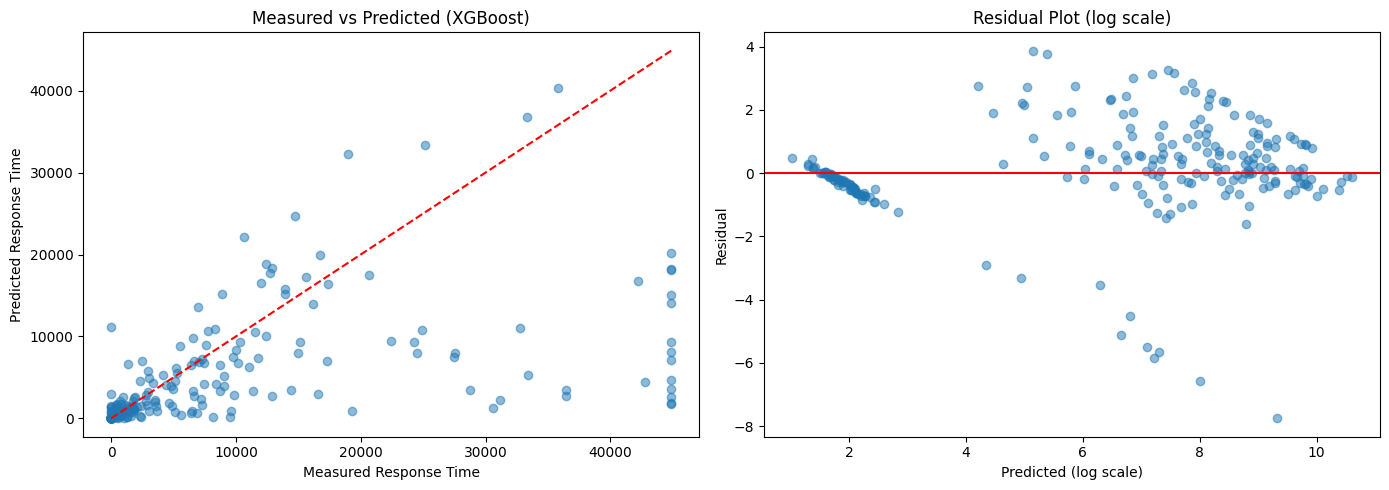

In [12]:
# Use whichever model scored best — swap `best_pred` as needed
best_name = 'XGBoost' if HAS_XGB else 'Gradient Boosting'
best_pred_log = y_pred_xgb if HAS_XGB else y_pred_gb
best_pred_raw = np.expm1(best_pred_log)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Measured vs Predicted
axes[0].scatter(y_test_raw, best_pred_raw, alpha=0.5)
lims = [min(y_test_raw.min(), best_pred_raw.min()),
        max(y_test_raw.max(), best_pred_raw.max())]
axes[0].plot(lims, lims, 'r--', lw=1.5)
axes[0].set_xlabel('Measured Response Time')
axes[0].set_ylabel('Predicted Response Time')
axes[0].set_title(f'Measured vs Predicted ({best_name})')

# Residual Plot (log scale — should show no pattern)
residuals = y_test - best_pred_log
axes[1].scatter(best_pred_log, residuals, alpha=0.5)
axes[1].axhline(0, color='red', lw=1.5)
axes[1].set_xlabel('Predicted (log scale)')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residual Plot (log scale)')

plt.tight_layout()
plt.show()

## 8. Feature Importance

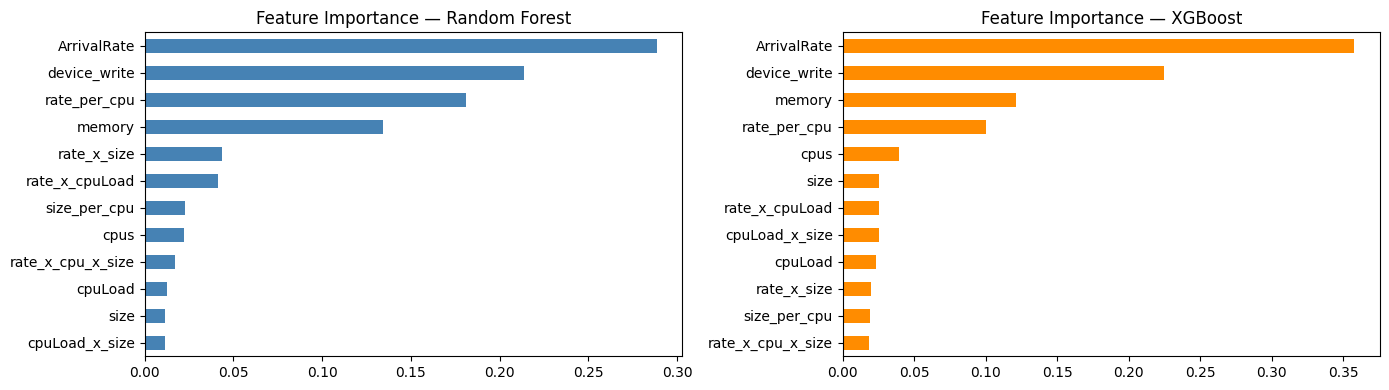

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# RF importance
rf_imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)
rf_imp.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Feature Importance — Random Forest')

# XGB or GB importance
if HAS_XGB:
    xgb_imp = pd.Series(xgb.feature_importances_, index=feature_cols).sort_values(ascending=True)
    xgb_imp.plot(kind='barh', ax=axes[1], color='darkorange')
    axes[1].set_title('Feature Importance — XGBoost')
else:
    gb_imp = pd.Series(gb.feature_importances_, index=feature_cols).sort_values(ascending=True)
    gb_imp.plot(kind='barh', ax=axes[1], color='darkorange')
    axes[1].set_title('Feature Importance — GradientBoosting')

plt.tight_layout()
plt.show()

## 9. Inference Example

In [14]:
raw_sample = {
    'ArrivalRate': 10,
    'cpus': 0.5,
    'cpuLoad': 100,
    'size': 250,
}

sample_df = add_features(pd.DataFrame([raw_sample]))

for col in feature_cols:
    if col not in sample_df.columns:
        sample_df[col] = 0
sample_df = sample_df[feature_cols]

best_model = xgb if HAS_XGB else gb
pred_log = best_model.predict(sample_df)
pred_raw = np.expm1(pred_log)
print(f'Input: {raw_sample}')
print(f'Predicted ResponseTime: {pred_raw[0]:.2f} ms')

Input: {'ArrivalRate': 10, 'cpus': 0.5, 'cpuLoad': 100, 'size': 250}
Predicted ResponseTime: 422.16 ms


ArrivalRate=1 => Predicted ResponseTime: 422.16 ms
ArrivalRate=5 => Predicted ResponseTime: 422.16 ms
ArrivalRate=8 => Predicted ResponseTime: 422.16 ms
ArrivalRate=10 => Predicted ResponseTime: 422.16 ms
ArrivalRate=12 => Predicted ResponseTime: 422.16 ms
ArrivalRate=15 => Predicted ResponseTime: 422.16 ms
ArrivalRate=18 => Predicted ResponseTime: 422.16 ms
ArrivalRate=20 => Predicted ResponseTime: 4094.64 ms
ArrivalRate=23 => Predicted ResponseTime: 4094.64 ms
ArrivalRate=25 => Predicted ResponseTime: 4094.64 ms


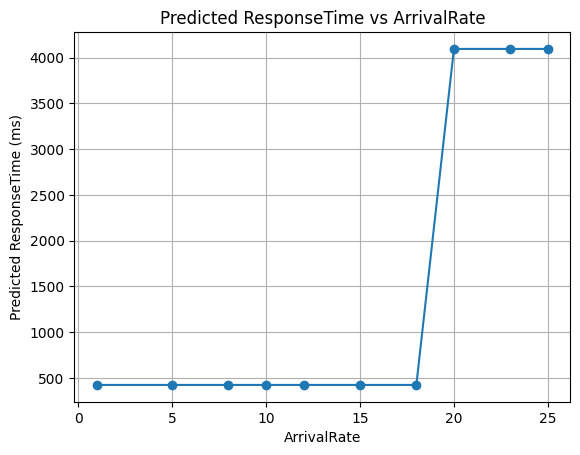

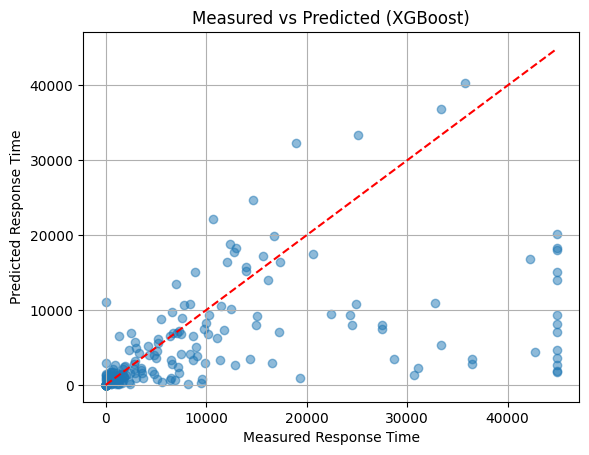

In [ ]:
samp = np.array(sample_df).astype(np.float32)

preds = []
irange = [1,5,8,10,12,15,18,20,23,25]
for i in irange:
    samp[0][0] = i
    pred_log = best_model.predict(samp)
    pred_raw = np.expm1(pred_log)
    preds.append(pred_raw[0])
    print(f'ArrivalRate={i} => Predicted ResponseTime: {pred_raw[0]:.2f} ms')
    
plt.plot(irange, preds, marker='o')
plt.plot()
plt.xlabel('ArrivalRate')
plt.ylabel('Predicted ResponseTime (ms)')
plt.title('Predicted ResponseTime vs ArrivalRate')
plt.grid()
plt.show()

In [16]:
# Diagnostic — run this and paste the output
print("=== ResponseTime distribution after cleaning ===")
print(df['ResponseTime'].describe(percentiles=[.25, .5, .75, .90, .95, .99]))

print("\n=== Value counts of key features ===")
for col in ['ArrivalRate', 'cpuLoad', 'size', 'cpus']:
    if col in df.columns:
        print(f"\n{col}:\n{df[col].value_counts().sort_index()}")

print("\n=== RT by ArrivalRate (median) ===")
print(df.groupby('ArrivalRate')['ResponseTime'].median())

print("\n=== RT by size (median) ===")
print(df.groupby('size')['ResponseTime'].median())

print("\n=== RT by cpuLoad (median) ===")
print(df.groupby('cpuLoad')['ResponseTime'].median())

print("\n=== Rows where RT < 10ms ===", (df['ResponseTime'] < 10).sum())
print("=== Rows where RT > 1000ms ===", (df['ResponseTime'] > 1000).sum())
print("=== Rows where RT > 10000ms ===", (df['ResponseTime'] > 10000).sum())

print("\n=== CV scores per model (copy from cell 6 output) ===")

=== ResponseTime distribution after cleaning ===
count     1191.000000
mean      7669.858522
std      12433.630078
min          2.400000
25%          4.100000
50%       1311.000000
75%       9548.650000
90%      27496.400000
95%      44694.025000
99%      44876.350000
max      44876.350000
Name: ResponseTime, dtype: float64

=== Value counts of key features ===

ArrivalRate:
ArrivalRate
10     243
20     243
40     236
75     231
100    238
Name: count, dtype: int64

cpuLoad:
cpuLoad
0       397
100     399
1000    395
Name: count, dtype: int64

size:
size
0       396
250     394
1000    401
Name: count, dtype: int64

cpus:
cpus
0.5    399
1.0    394
2.0    398
Name: count, dtype: int64

=== RT by ArrivalRate (median) ===
ArrivalRate
10        4.10
20       76.60
40     1271.85
75     5699.90
100    7826.65
Name: ResponseTime, dtype: float64

=== RT by size (median) ===
size
0       1304.1
250     1891.6
1000    1117.6
Name: ResponseTime, dtype: float64

=== RT by cpuLoad (median) ===
